In [1]:
import os, glob, struct, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

CFG = {
    "n_images": 1024,          # images sampled from the full 70,000
    "test_frac": 0.2,          # 80% train (819 images) / 20% test (205 images)
    "latent_shape": (3, 4, 4),
    "batch_size": 64,
    "epochs": 1500,
    "lr": 1e-3,
    "lr_min": 1e-5,
    "beta_max": 1e-3,
    "beta_warmup": 200,        # epochs to ramp beta from 0 to beta_max
    "eval_every": 50,
    "seed": 811,
}

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
torch.cuda.manual_seed_all(CFG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Turn on the GPU in Settings -> Accelerator before training.")

Device: cuda


In [12]:
import pandas as pd
from IPython.display import display

def _fmt(shape, batch):
    return " × ".join("N" if (i == 0 and s == batch) else str(s) for i, s in enumerate(shape))

def _pair(v):
    if isinstance(v, str):
        return v
    if isinstance(v, (tuple, list)):
        return str(v[0]) if len(set(v)) == 1 else " × ".join(map(str, v))
    return str(v)

def _weight(mod):
    if isinstance(mod, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear, nn.Embedding)):
        return " × ".join(map(str, mod.weight.shape))
    if isinstance(mod, nn.BatchNorm2d):
        return str(mod.num_features)
    if isinstance(mod, nn.LayerNorm):
        return " × ".join(map(str, mod.normalized_shape))
    if isinstance(mod, nn.MultiheadAttention):
        return f"{mod.embed_dim} ({mod.num_heads} heads)"
    if isinstance(mod, (nn.MaxPool2d, nn.AvgPool2d)):
        k = mod.kernel_size
        return f"{k} × {k}" if isinstance(k, int) else _pair(k)
    return "-"

def show_arch(m, x, title):
    """m: model, x: one example input batch (batch size 1), title: heading."""
    mha = [n for n, mod in m.named_modules() if isinstance(mod, nn.MultiheadAttention)]

    def tracked(name, mod):
        if any(name.startswith(p + ".") for p in mha):      # skip inside attention
            return False
        return len(list(mod.children())) == 0 or isinstance(mod, nn.MultiheadAttention)

    records, hooks = {}, []
    for name, mod in m.named_modules():
        if name and tracked(name, mod):
            def hook(mod, inp, out, name=name):
                if name not in records:
                    o = out[0] if isinstance(out, tuple) else out
                    records[name] = (mod, tuple(o.shape))
            hooks.append(mod.register_forward_hook(hook))

    was_training = m.training
    m.eval()                                   # eval so BatchNorm stats are not changed
    with torch.enable_grad():                  # keeps the Transformer on its normal path
        m(x)
    m.train(was_training)
    for h in hooks:
        h.remove()

    batch = x.shape[0]
    rows = [("input", "Input", "-", "-", "-", _fmt(x.shape, batch), 0)]
    for name, (mod, shape) in records.items():
        has_conv = isinstance(mod, (nn.Conv2d, nn.ConvTranspose2d, nn.MaxPool2d, nn.AvgPool2d))
        rows.append((
            name,
            mod.__class__.__name__,
            _weight(mod),
            _pair(mod.stride) if has_conv else "-",
            _pair(mod.padding) if has_conv else "-",
            _fmt(shape, batch),
            sum(p.numel() for p in mod.parameters()),
        ))

    df = pd.DataFrame(rows, columns=["Layer", "Type", "Weight", "Stride", "Padding",
                                     "Output size", "Params"])
    print(title)
    display(df.style.hide(axis="index"))
    print(f"Total parameters: {sum(p.numel() for p in m.parameters()):,}")

In [4]:
def read_idx(path):
    with open(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        n_dims = magic & 0xFF
        shape = struct.unpack(">" + "I" * n_dims, f.read(4 * n_dims))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

def find(pattern):
    hits = [h for h in glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
            if os.path.isfile(h)]
    if not hits:
        raise FileNotFoundError(pattern)
    return sorted(hits)[0]

images = np.concatenate([read_idx(find("train-images.idx3-ubyte")),
                         read_idx(find("t10k-images.idx3-ubyte"))])
labels = np.concatenate([read_idx(find("train-labels.idx1-ubyte")),
                         read_idx(find("t10k-labels.idx1-ubyte"))]).astype(np.int64)

idx, _ = train_test_split(np.arange(len(labels)), train_size=CFG["n_images"],
                          stratify=labels, random_state=CFG["seed"])

train_idx, test_idx = train_test_split(idx, test_size=CFG["test_frac"],
                                       stratify=labels[idx], random_state=CFG["seed"])

def to_tensor(arr):
    return torch.from_numpy(arr.copy()).float().div(255.0).unsqueeze(1) * 2 - 1

x_train, y_train = to_tensor(images[train_idx]), labels[train_idx]
x_test,  y_test  = to_tensor(images[test_idx]),  labels[test_idx]

loader = DataLoader(TensorDataset(x_train), batch_size=CFG["batch_size"], shuffle=True)

print("Train:", tuple(x_train.shape), " Test:", tuple(x_test.shape))
print("Train per class:", np.bincount(y_train, minlength=10))
print("Test  per class:", np.bincount(y_test, minlength=10))

Train: (819, 1, 28, 28)  Test: (205, 1, 28, 28)
Train per class: [81 92 81 83 80 74 81 85 80 82]
Test  per class: [20 23 21 21 20 18 20 22 20 20]


In [5]:
class BinaryVAE(nn.Module):
    def __init__(self, latent_shape=(3, 4, 4)):
        super().__init__()
        self.latent_shape = latent_shape
        self.n_latent = int(np.prod(latent_shape))   # 3 * 4 * 4 = 48 bits

        # ---------------- Encoder ----------------
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1),    # 28 -> 14
            nn.BatchNorm2d(32), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),   # 14 -> 7
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),  # 7 -> 4
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
        )
        self.enc_fc = nn.Sequential(
            nn.Flatten(),                                # 128 * 4 * 4 = 2048
            nn.Linear(128 * 4 * 4, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 2 * self.n_latent),           # 48 for mu + 48 for log-variance
        )

        # ---------------- Decoder ----------------
        self.dec_fc = nn.Sequential(
            nn.Flatten(),                                # 3 x 4 x 4 -> 48
            nn.Linear(self.n_latent, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 128 * 7 * 7), nn.LeakyReLU(0.2),
            nn.Unflatten(1, (128, 7, 7)),
        )
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 7 -> 14
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),   # 14 -> 28
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 1, 3, padding=1),                       # 28 -> 28
            nn.Tanh(),
        )

    def encode(self, x):
        h = self.enc_fc(self.enc_conv(x))
        mu, logvar = h.chunk(2, dim=1)
        logvar = logvar.clamp(-10, 5)
        return mu.view(-1, *self.latent_shape), logvar.view(-1, *self.latent_shape)

    @staticmethod
    def binarize(h):
        soft = torch.tanh(h)
        hard = torch.where(soft >= 0, torch.ones_like(soft), -torch.ones_like(soft))
        return soft + (hard - soft).detach()

    def decode(self, z):
        return self.dec_conv(self.dec_fc(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        if self.training:
            h = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        else:
            h = mu
        z = self.binarize(h)
        return self.decode(z), z, mu, logvar


model = BinaryVAE(CFG["latent_shape"]).to(DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 4612865


In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"],
                                                       eta_min=CFG["lr_min"])

def kl_divergence(mu, logvar):
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=(1, 2, 3)).mean()

@torch.no_grad()
def average_psnr(model, x, batch=512):
    model.eval()
    scores = []
    for i in range(0, len(x), batch):
        xb = x[i:i + batch].to(DEVICE)
        x_hat, _, _, _ = model(xb)
        orig, rec = (xb + 1) / 2, (x_hat + 1) / 2
        mse = ((rec - orig) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)
        scores.append(10 * torch.log10(1.0 / mse))
    model.train()
    return torch.cat(scores).mean().item()

history = {"epoch": [], "recon": [], "kl": [], "train_psnr": [], "test_psnr": []}
start = time.time()

for epoch in range(1, CFG["epochs"] + 1):
    beta = CFG["beta_max"] * min(1.0, epoch / CFG["beta_warmup"])
    rec_sum, kl_sum, n = 0.0, 0.0, 0
    for (xb,) in loader:
        xb = xb.to(DEVICE)
        x_hat, z, mu, logvar = model(xb)
        recon = F.mse_loss(x_hat, xb, reduction="none").sum(dim=(1, 2, 3)).mean()
        kl = kl_divergence(mu, logvar)
        loss = recon + beta * kl
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        rec_sum += recon.item() * len(xb)
        kl_sum  += kl.item() * len(xb)
        n       += len(xb)
    scheduler.step()

    if epoch % CFG["eval_every"] == 0 or epoch == 1:
        train_psnr = average_psnr(model, x_train)
        test_psnr  = average_psnr(model, x_test)
        for k, v in zip(history, [epoch, rec_sum / n, kl_sum / n, train_psnr, test_psnr]):
            history[k].append(v)
        print(f"epoch {epoch:5d} | recon {rec_sum/n:7.3f} | KL {kl_sum/n:7.2f} "
              f"| train {train_psnr:6.2f} dB | test {test_psnr:6.2f} dB "
              f"| {(time.time() - start)/60:5.1f} min")

epoch     1 | recon 397.026 | KL 1334.28 | train  11.37 dB | test  11.25 dB |   0.0 min
epoch    50 | recon  33.992 | KL  269.05 | train  20.35 dB | test  16.50 dB |   0.1 min
epoch   100 | recon   8.568 | KL  329.71 | train  26.48 dB | test  16.36 dB |   0.2 min
epoch   150 | recon   4.405 | KL  312.29 | train  29.66 dB | test  16.34 dB |   0.3 min
epoch   200 | recon   3.019 | KL  260.41 | train  31.31 dB | test  16.30 dB |   0.3 min
epoch   250 | recon   3.186 | KL  246.15 | train  31.46 dB | test  16.27 dB |   0.4 min
epoch   300 | recon   1.587 | KL  222.05 | train  34.43 dB | test  16.36 dB |   0.5 min
epoch   350 | recon   1.986 | KL  239.47 | train  33.38 dB | test  16.36 dB |   0.6 min
epoch   400 | recon   1.468 | KL  206.55 | train  34.73 dB | test  16.38 dB |   0.6 min
epoch   450 | recon   0.972 | KL  194.02 | train  36.34 dB | test  16.39 dB |   0.7 min
epoch   500 | recon   0.728 | KL  198.54 | train  37.95 dB | test  16.34 dB |   0.8 min
epoch   550 | recon   0.643 | KL

Average PSNR, training set (819 images): 48.53 dB
Average PSNR, test set     (205 images): 16.29 dB


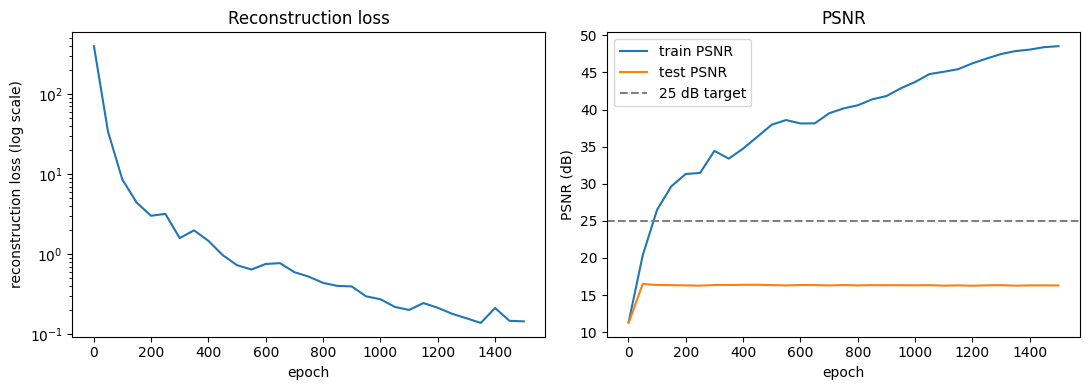

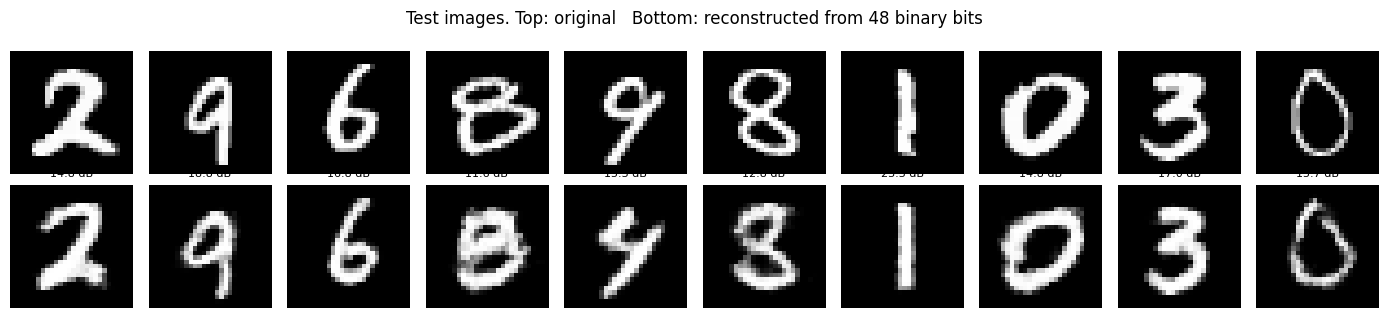

In [8]:
final_train = average_psnr(model, x_train)
final_test  = average_psnr(model, x_test)
print(f"Average PSNR, training set ({len(x_train)} images): {final_train:.2f} dB")
print(f"Average PSNR, test set     ({len(x_test)} images): {final_test:.2f} dB")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(history["epoch"], history["recon"]); a1.set_yscale("log")
a1.set_xlabel("epoch"); a1.set_ylabel("reconstruction loss (log scale)"); a1.set_title("Reconstruction loss")
a2.plot(history["epoch"], history["train_psnr"], label="train PSNR")
a2.plot(history["epoch"], history["test_psnr"], label="test PSNR")
a2.axhline(25, ls="--", c="gray", label="25 dB target")
a2.set_xlabel("epoch"); a2.set_ylabel("PSNR (dB)"); a2.legend(); a2.set_title("PSNR")
plt.tight_layout(); plt.savefig("q2_1024split_curves.png", dpi=150); plt.show()

model.eval()
with torch.no_grad():
    sample = x_test[:10].to(DEVICE)
    recon, _, _, _ = model(sample)
model.train()
orig01, rec01 = (sample + 1) / 2, (recon + 1) / 2
img_psnr = 10 * torch.log10(1 / ((rec01 - orig01) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10))

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i in range(10):
    axes[0, i].imshow(orig01[i, 0].cpu(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(rec01[i, 0].cpu(), cmap="gray");  axes[1, i].axis("off")
    axes[1, i].set_title(f"{img_psnr[i]:.1f} dB", fontsize=8)
plt.suptitle("Test images. Top: original   Bottom: reconstructed from 48 binary bits")
plt.tight_layout(); plt.savefig("q2_1024split_test_reconstructions.png", dpi=150); plt.show()

In [15]:
show_arch(model, x_train[:1].to(DEVICE), "Q2: BinaryVAE")

Q2: BinaryVAE


Layer,Type,Weight,Stride,Padding,Output size,Params
input,Input,-,-,-,N × 1 × 28 × 28,0
enc_conv.0,Conv2d,32 × 1 × 4 × 4,2,1,N × 32 × 14 × 14,544
enc_conv.1,BatchNorm2d,32,-,-,N × 32 × 14 × 14,64
enc_conv.2,LeakyReLU,-,-,-,N × 32 × 14 × 14,0
enc_conv.3,Conv2d,64 × 32 × 4 × 4,2,1,N × 64 × 7 × 7,32832
enc_conv.4,BatchNorm2d,64,-,-,N × 64 × 7 × 7,128
enc_conv.5,LeakyReLU,-,-,-,N × 64 × 7 × 7,0
enc_conv.6,Conv2d,128 × 64 × 3 × 3,2,1,N × 128 × 4 × 4,73856
enc_conv.7,BatchNorm2d,128,-,-,N × 128 × 4 × 4,256
enc_conv.8,LeakyReLU,-,-,-,N × 128 × 4 × 4,0


Total parameters: 4,612,865


# Q3: Tokens from the Question 2 model

In [16]:
# ================= Question 3 =================
vae = model                                         # the trained binary VAE from Question 2
print(f"Q2 average PSNR on the encoded images: {average_psnr(vae, x_train):.2f} dB")

vae.eval()
with torch.no_grad():
    _, z_all, _, _ = vae(x_train.to(DEVICE))        # 819 x 3 x 4 x 4, values -1/+1

bits = (z_all > 0).long().cpu()                     # +1 -> 1, -1 -> 0
tokens = (bits * torch.tensor([4, 2, 1]).view(1, 3, 1, 1)).sum(dim=1).view(len(bits), -1)   # 819 x 16, values 0..7

VOCAB, SEQ_LEN = 8, tokens.shape[1]                 # 8 possible tokens, 16 tokens per image
PAD = BOS = VOCAB                                   # extra index 8: padding (Parts A, C) / start token (Part B)

print("Token sequences:", tuple(tokens.shape))
print("Unique sequences:", len(set(map(tuple, tokens.tolist()))), "/", len(tokens))
print("First sequence:", tokens[0].tolist())

Q2 average PSNR on the encoded images: 48.53 dB
Token sequences: (819, 16)
Unique sequences: 819 / 819
First sequence: [5, 4, 5, 0, 0, 3, 1, 0, 7, 0, 2, 5, 3, 2, 0, 1]


**Q3: Helper functions**

In [17]:
def left_pad(prefix):                               # N x i  ->  N x 15, PAD values in front
    n, i = prefix.shape
    pad = torch.full((n, SEQ_LEN - 1 - i), PAD, dtype=torch.long, device=prefix.device)
    return torch.cat([pad, prefix], dim=1)

def tokens_to_latent(tok):                          # N x 16 tokens -> N x 3 x 4 x 4 latent (-1/+1)
    b = torch.stack([(tok >> 2) & 1, (tok >> 1) & 1, tok & 1], dim=1)
    return (b.float() * 2 - 1).view(-1, 3, 4, 4)

print("Token -> latent conversion is exact:", torch.equal(tokens_to_latent(tokens) > 0, z_all.cpu() > 0))

@torch.no_grad()
def show_generated(tok, title, fname, n=16):
    imgs = (vae.decode(tokens_to_latent(tok[:n].cpu()).to(DEVICE)) + 1) / 2
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 0.9, 2.2))
    for ax, im in zip(axes.flat, imgs):
        ax.imshow(im[0].cpu(), cmap="gray"); ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def memorization(generated, train_tokens):
    train_set = set(map(tuple, train_tokens.tolist()))
    gen = list(map(tuple, generated.tolist()))
    return sum(g in train_set for g in gen) / len(gen), len(set(gen))

Token -> latent conversion is exact: True


# Part A: Sequence to Token (classification network + cross-entropy)

**Q3 Cell A1: Training pairs**

In [18]:
train_A = tokens[:100]                                                     # 100 sequences
X_A = torch.cat([left_pad(train_A[:, :i]) for i in range(0, SEQ_LEN)])     # prefixes (incl. empty), 1600 x 15
Y_A = torch.cat([train_A[:, i] for i in range(0, SEQ_LEN)])                # next token, 1600
loader_A = DataLoader(TensorDataset(X_A, Y_A), batch_size=128, shuffle=True)
print("Training pairs:", tuple(X_A.shape), tuple(Y_A.shape))

Training pairs: (1600, 15) (1600,)


**Q3 Cell A2: The classification network**

In [19]:
class PrefixClassifier(nn.Module):
    def __init__(self, emb=32, hidden=512):
        super().__init__()
        self.embed = nn.Embedding(VOCAB + 1, emb)               # 8 tokens + PAD
        self.net = nn.Sequential(
            nn.Flatten(),                                       # N x 15 x 32 -> N x 480
            nn.Linear((SEQ_LEN - 1) * emb, hidden), nn.ReLU(),  # encoder: prefix -> feature vector
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, VOCAB),                           # classifier head: 8 scores
        )

    def forward(self, x):                                       # x: N x 15
        return self.net(self.embed(x))

model_A = PrefixClassifier().to(DEVICE)
print("Parameters:", sum(p.numel() for p in model_A.parameters()))

Parameters: 513320


**Q3 Cell A3: Training with cross-entropy**

In [20]:
opt_A = torch.optim.Adam(model_A.parameters(), lr=1e-3)
for epoch in range(1, 301):
    for xb, yb in loader_A:
        loss = F.cross_entropy(model_A(xb.to(DEVICE)), yb.to(DEVICE))
        opt_A.zero_grad(); loss.backward(); opt_A.step()

    if epoch % 25 == 0 or epoch == 1:
        model_A.eval()
        with torch.no_grad():
            logits = model_A(X_A.to(DEVICE))
            acc = (logits.argmax(1) == Y_A.to(DEVICE)).float().mean().item()
            ce = F.cross_entropy(logits, Y_A.to(DEVICE)).item()
        model_A.train()
        print(f"epoch {epoch:4d} | loss {ce:.4f} | next-token accuracy {acc:.2%}")

epoch    1 | loss 1.9696 | next-token accuracy 30.19%
epoch   25 | loss 0.3312 | next-token accuracy 87.00%
epoch   50 | loss 0.4138 | next-token accuracy 84.56%
epoch   75 | loss 0.2954 | next-token accuracy 87.00%
epoch  100 | loss 0.2934 | next-token accuracy 87.00%
epoch  125 | loss 0.2920 | next-token accuracy 87.06%
epoch  150 | loss 0.2929 | next-token accuracy 87.00%
epoch  175 | loss 0.2910 | next-token accuracy 87.06%
epoch  200 | loss 0.2906 | next-token accuracy 87.06%
epoch  225 | loss 0.2906 | next-token accuracy 87.00%
epoch  250 | loss 0.2908 | next-token accuracy 87.06%
epoch  275 | loss 0.2894 | next-token accuracy 87.06%
epoch  300 | loss 0.2892 | next-token accuracy 87.06%


**Q3 Cell A4: Generation**

Sequence to Token: 99.0% of 100 generated sequences are training sequences (61 distinct)
Target (> 80%): MET


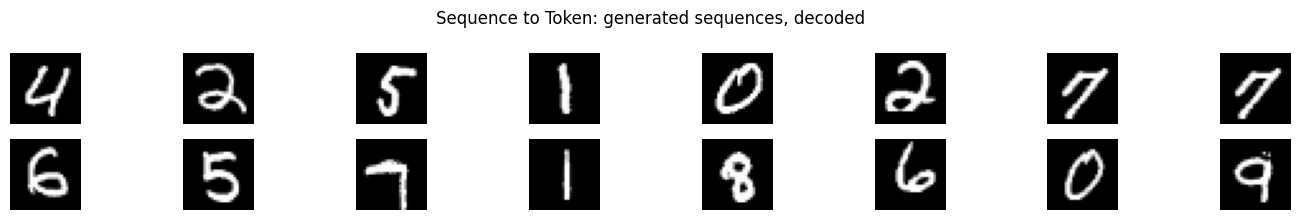

In [21]:
@torch.no_grad()
def generate_A(model, n=100, temperature=1.0):
    model.eval()
    seqs = torch.empty((n, 0), dtype=torch.long, device=DEVICE)        # start with no tokens
    for i in range(SEQ_LEN):
        logits = model(left_pad(seqs)) / temperature
        probs = F.softmax(logits, dim=1)                                # predicted distribution
        nxt = torch.multinomial(probs, 1)                               # sample, don't argmax
        seqs = torch.cat([seqs, nxt], dim=1)
    model.train()
    return seqs.cpu()

gen_A = generate_A(model_A)
rate_A, distinct_A = memorization(gen_A, train_A)
print(f"Sequence to Token: {rate_A:.1%} of {len(gen_A)} generated sequences are training sequences "
      f"({distinct_A} distinct)")
print("Target (> 80%):", "MET" if rate_A > 0.8 else "NOT MET")
show_generated(gen_A, "Sequence to Token: generated sequences, decoded", "q3_seq2token.png")

In [22]:
show_arch(model_A, left_pad(torch.empty((1, 0), dtype=torch.long)).to(DEVICE),
          "Q3 Part A: Sequence to Token (PrefixClassifier)")

Q3 Part A: Sequence to Token (PrefixClassifier)


Layer,Type,Weight,Stride,Padding,Output size,Params
input,Input,-,-,-,N × 15,0
embed,Embedding,9 × 32,-,-,N × 15 × 32,288
net.0,Flatten,-,-,-,N × 480,0
net.1,Linear,512 × 480,-,-,N × 512,246272
net.2,ReLU,-,-,-,N × 512,0
net.3,Linear,512 × 512,-,-,N × 512,262656
net.4,ReLU,-,-,-,N × 512,0
net.5,Linear,8 × 512,-,-,N × 8,4104


Total parameters: 513,320


# Part B: Sequence to Sequence (Transformer decoder with causal mask)

**Q3 Cell B1: Shifted input and target**

In [23]:
train_B = tokens[:100]
inp_B = torch.cat([torch.full((len(train_B), 1), BOS), train_B[:, :-1]], dim=1)   # BOS, z1 ... z15
tgt_B = train_B                                                                   # z1 ... z16
loader_B = DataLoader(TensorDataset(inp_B, tgt_B), batch_size=20, shuffle=True)
print("Example input :", inp_B[0].tolist())
print("Example target:", tgt_B[0].tolist())

Example input : [8, 5, 4, 5, 0, 0, 3, 1, 0, 7, 0, 2, 5, 3, 2, 0]
Example target: [5, 4, 5, 0, 0, 3, 1, 0, 7, 0, 2, 5, 3, 2, 0, 1]


**Q3 Cell B2: The Transformer decoder**

In [24]:
class Seq2SeqTransformer(nn.Module):
    def __init__(self, d_model=128, n_heads=4, n_layers=4):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB + 1, d_model)              # 8 tokens + BOS
        self.pos_emb = nn.Embedding(SEQ_LEN, d_model)                # one vector per position
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward=4 * d_model,
                                           dropout=0.0, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, VOCAB)
        self.register_buffer("causal_mask",
                             torch.triu(torch.ones(SEQ_LEN, SEQ_LEN, dtype=torch.bool), diagonal=1))

    def forward(self, x):                                            # x: N x L, L <= 16
        L = x.size(1)
        h = self.tok_emb(x) + self.pos_emb(torch.arange(L, device=x.device))
        h = self.blocks(h, mask=self.causal_mask[:L, :L])            # each position sees only earlier ones
        return self.head(h)                                          # N x L x 8

model_B = Seq2SeqTransformer().to(DEVICE)
print("Parameters:", sum(p.numel() for p in model_B.parameters()))
print("Causal mask, first 5 positions (1 = blocked):\n", model_B.causal_mask[:5, :5].int())

Parameters: 797320
Causal mask, first 5 positions (1 = blocked):
 tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], device='cuda:0', dtype=torch.int32)


**Q3 Cell B3: Training with cross-entropy at every position**

In [25]:
opt_B = torch.optim.Adam(model_B.parameters(), lr=5e-4)
for epoch in range(1, 501):
    for xb, yb in loader_B:
        logits = model_B(xb.to(DEVICE))
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), yb.to(DEVICE).reshape(-1))
        opt_B.zero_grad(); loss.backward(); opt_B.step()

    if epoch % 50 == 0 or epoch == 1:
        model_B.eval()
        with torch.no_grad():
            logits = model_B(inp_B.to(DEVICE))
            acc = (logits.argmax(-1) == tgt_B.to(DEVICE)).float().mean().item()
            ce = F.cross_entropy(logits.reshape(-1, VOCAB), tgt_B.to(DEVICE).reshape(-1)).item()
        model_B.train()
        print(f"epoch {epoch:4d} | loss {ce:.4f} | token accuracy {acc:.2%}")

epoch    1 | loss 2.0412 | token accuracy 17.50%
epoch   50 | loss 0.3040 | token accuracy 86.81%
epoch  100 | loss 0.2976 | token accuracy 86.75%
epoch  150 | loss 0.2931 | token accuracy 87.06%
epoch  200 | loss 0.2920 | token accuracy 87.06%
epoch  250 | loss 0.2911 | token accuracy 87.06%
epoch  300 | loss 0.2910 | token accuracy 87.06%
epoch  350 | loss 0.2902 | token accuracy 87.06%
epoch  400 | loss 0.2943 | token accuracy 86.94%
epoch  450 | loss 0.2904 | token accuracy 87.06%
epoch  500 | loss 0.2901 | token accuracy 87.06%


**Q3 Cell B4: Generation**

Sequence to Sequence: 98.0% of 100 generated sequences are training sequences (63 distinct)
Target (> 80%): MET


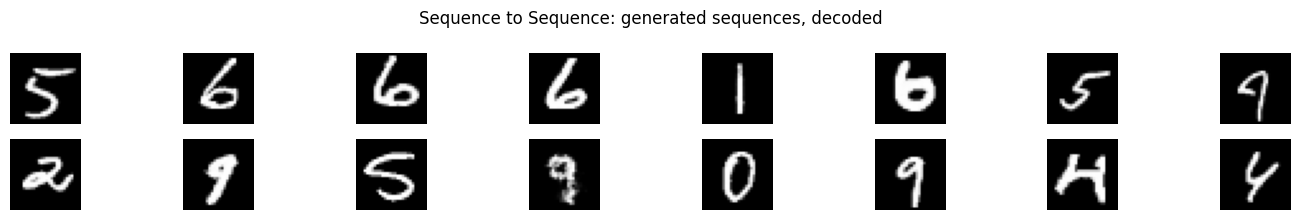

In [26]:
@torch.no_grad()
def generate_B(model, n=100, temperature=1.0):
    model.eval()
    seqs = torch.full((n, 1), BOS, device=DEVICE)                    # every sequence starts with BOS
    for i in range(SEQ_LEN):
        probs = F.softmax(model(seqs)[:, -1] / temperature, dim=1)   # next-token probabilities
        seqs = torch.cat([seqs, torch.multinomial(probs, 1)], dim=1)
    model.train()
    return seqs[:, 1:].cpu()                                         # drop BOS

gen_B = generate_B(model_B)
rate_B, distinct_B = memorization(gen_B, train_B)
print(f"Sequence to Sequence: {rate_B:.1%} of {len(gen_B)} generated sequences are training sequences "
      f"({distinct_B} distinct)")
print("Target (> 80%):", "MET" if rate_B > 0.8 else "NOT MET")
show_generated(gen_B, "Sequence to Sequence: generated sequences, decoded", "q3_seq2seq.png")

In [27]:
show_arch(model_B, inp_B[:1].to(DEVICE),
          "Q3 Part B: Sequence to Sequence (Seq2SeqTransformer)")

Q3 Part B: Sequence to Sequence (Seq2SeqTransformer)


Layer,Type,Weight,Stride,Padding,Output size,Params
input,Input,-,-,-,N × 16,0
tok_emb,Embedding,9 × 128,-,-,N × 16 × 128,1152
pos_emb,Embedding,16 × 128,-,-,16 × 128,2048
blocks.layers.0.self_attn,MultiheadAttention,128 (4 heads),-,-,N × 16 × 128,66048
blocks.layers.0.dropout1,Dropout,-,-,-,N × 16 × 128,0
blocks.layers.0.norm1,LayerNorm,128,-,-,N × 16 × 128,256
blocks.layers.0.linear1,Linear,512 × 128,-,-,N × 16 × 512,66048
blocks.layers.0.dropout,Dropout,-,-,-,N × 16 × 512,0
blocks.layers.0.linear2,Linear,128 × 512,-,-,N × 16 × 128,65664
blocks.layers.0.dropout2,Dropout,-,-,-,N × 16 × 128,0


Total parameters: 797,320


# Part C: Sequence to Histogram (KL divergence)

**Q3 Cell C1: Real next-token histograms**

In [28]:
train_C = tokens                                                 # all 819 sequences (> 512 required)

counts = {}
for seq in train_C.tolist():
    for i in range(SEQ_LEN):                                     # prefix lengths 0 .. 15
        key = tuple(seq[:i])
        counts.setdefault(key, torch.zeros(VOCAB))[seq[i]] += 1

X_C = torch.cat([left_pad(torch.tensor([p], dtype=torch.long)) for p in counts])   # one row per prefix
H_C = torch.stack([c / c.sum() for c in counts.values()])                          # each row sums to 1
loader_C = DataLoader(TensorDataset(X_C, H_C), batch_size=256, shuffle=True)

print("Distinct prefixes:", len(X_C))
print("First-token histogram:", [round(v, 3) for v in (counts[()] / counts[()].sum()).tolist()])

Distinct prefixes: 9785
First-token histogram: [0.095, 0.138, 0.143, 0.044, 0.106, 0.173, 0.161, 0.139]


**Q3 Cell C2: The model**

In [29]:
model_C = PrefixClassifier(hidden=1024).to(DEVICE)                # same network as Part A, wider
print("Parameters:", sum(p.numel() for p in model_C.parameters()))

Parameters: 1550632


**Q3 Cell C3: Training with KL divergence**

In [30]:
EPOCHS_C = 300
opt_C = torch.optim.Adam(model_C.parameters(), lr=1e-3)
sched_C = torch.optim.lr_scheduler.CosineAnnealingLR(opt_C, T_max=EPOCHS_C)

for epoch in range(1, EPOCHS_C + 1):
    for xb, hb in loader_C:
        log_p = F.log_softmax(model_C(xb.to(DEVICE)), dim=1)          # predicted histogram (log)
        loss = F.kl_div(log_p, hb.to(DEVICE), reduction="batchmean")   # KL(real || predicted)
        opt_C.zero_grad(); loss.backward(); opt_C.step()
    sched_C.step()

    if epoch % 25 == 0 or epoch == 1:
        model_C.eval()
        with torch.no_grad():
            kl = F.kl_div(F.log_softmax(model_C(X_C.to(DEVICE)), dim=1),
                          H_C.to(DEVICE), reduction="batchmean").item()
        model_C.train()
        print(f"epoch {epoch:4d} | KL divergence {kl:.5f}")

epoch    1 | KL divergence 1.71934
epoch   25 | KL divergence 0.03229
epoch   50 | KL divergence 0.01468
epoch   75 | KL divergence 0.00924
epoch  100 | KL divergence 0.00716
epoch  125 | KL divergence 0.00516
epoch  150 | KL divergence 0.00347
epoch  175 | KL divergence 0.00170
epoch  200 | KL divergence 0.00077
epoch  225 | KL divergence 0.00029
epoch  250 | KL divergence 0.00012
epoch  275 | KL divergence 0.00009
epoch  300 | KL divergence 0.00009


**Q3 Cell C4: Generation and the histogram figure**

Sequence to Histogram: 99.40% of 1000 generated sequences are training sequences (589 distinct)
Target (> 99%): MET


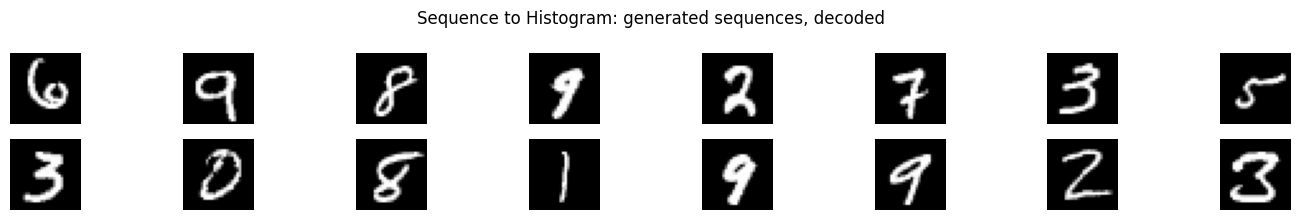

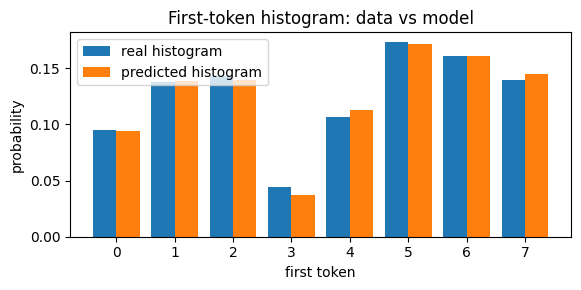

In [31]:
@torch.no_grad()
def generate_C(model, n=1000, temperature=1.0):
    model.eval()
    seqs = torch.empty((n, 0), dtype=torch.long, device=DEVICE)      # start with no tokens
    for i in range(SEQ_LEN):
        hist = F.softmax(model(left_pad(seqs)) / temperature, dim=1)   # predicted histogram
        seqs = torch.cat([seqs, torch.multinomial(hist, 1)], dim=1)    # sample from it
    model.train()
    return seqs.cpu()

gen_C = generate_C(model_C)
rate_C, distinct_C = memorization(gen_C, train_C)
print(f"Sequence to Histogram: {rate_C:.2%} of {len(gen_C)} generated sequences are training sequences "
      f"({distinct_C} distinct)")
print("Target (> 99%):", "MET" if rate_C > 0.99 else "NOT MET")
show_generated(gen_C, "Sequence to Histogram: generated sequences, decoded", "q3_seq2hist.png")

model_C.eval()
with torch.no_grad():
    pred_first = F.softmax(model_C(left_pad(torch.empty((1, 0), dtype=torch.long, device=DEVICE))), dim=1)[0].cpu()
model_C.train()
real_first = counts[()] / counts[()].sum()
plt.figure(figsize=(6, 3))
plt.bar(np.arange(VOCAB) - 0.2, real_first, width=0.4, label="real histogram")
plt.bar(np.arange(VOCAB) + 0.2, pred_first, width=0.4, label="predicted histogram")
plt.xlabel("first token"); plt.ylabel("probability"); plt.legend()
plt.title("First-token histogram: data vs model")
plt.tight_layout(); plt.savefig("q3_first_token_histogram.png", dpi=150); plt.show()

In [32]:
show_arch(model_C, left_pad(torch.empty((1, 0), dtype=torch.long)).to(DEVICE),
          "Q3 Part C: Sequence to Histogram (PrefixClassifier, hidden=1024)")

Q3 Part C: Sequence to Histogram (PrefixClassifier, hidden=1024)


Layer,Type,Weight,Stride,Padding,Output size,Params
input,Input,-,-,-,N × 15,0
embed,Embedding,9 × 32,-,-,N × 15 × 32,288
net.0,Flatten,-,-,-,N × 480,0
net.1,Linear,1024 × 480,-,-,N × 1024,492544
net.2,ReLU,-,-,-,N × 1024,0
net.3,Linear,1024 × 1024,-,-,N × 1024,1049600
net.4,ReLU,-,-,-,N × 1024,0
net.5,Linear,8 × 1024,-,-,N × 8,8200


Total parameters: 1,550,632
